In [2]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import *

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import *
from sklearn.preprocessing import *
from sklearn.feature_selection import *
from sklearn.decomposition import *
from sklearn.linear_model import *
from sklearn.svm import *
from sklearn.neighbors import *
from sklearn.tree import *
from sklearn.ensemble import *
from sklearn.neural_network import *
from sklearn.metrics import *


In [4]:
df = pd.read_csv("Student.csv")

In [5]:
df.head()
df.shape
df.columns


Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities',
       'internet', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [6]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,studytime,failures,schoolsup,famsup,paid,activities,internet,health,absences,G1,G2,G3
0,GP,F,22.0,Rural,GT3,A,1,1,2.0,3,no,yes,no,no,yes,2,2.0,7.1,6.0,3.6
1,GP,F,18.0,Urban,GT3,T,4,0,3.0,0,no,yes,no,no,no,2,2.0,10.7,12.6,14.8
2,MS,M,22.0,Rural,LE3,T,0,1,3.0,0,no,yes,no,no,no,3,2.0,9.3,12.6,14.1
3,GP,M,21.0,Urban,LE3,T,2,4,3.0,0,no,yes,yes,no,yes,4,2.0,11.2,8.6,11.0
4,GP,M,20.0,Urban,GT3,T,4,1,3.0,0,no,no,no,no,yes,2,5.0,13.5,12.1,11.8


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      400 non-null    str    
 1   sex         400 non-null    str    
 2   age         392 non-null    float64
 3   address     400 non-null    str    
 4   famsize     400 non-null    str    
 5   Pstatus     400 non-null    str    
 6   Medu        400 non-null    int64  
 7   Fedu        400 non-null    int64  
 8   studytime   392 non-null    float64
 9   failures    400 non-null    int64  
 10  schoolsup   400 non-null    str    
 11  famsup      400 non-null    str    
 12  paid        400 non-null    str    
 13  activities  400 non-null    str    
 14  internet    390 non-null    str    
 15  health      400 non-null    int64  
 16  absences    392 non-null    float64
 17  G1          400 non-null    float64
 18  G2          394 non-null    float64
 19  G3          400 non-null    float64
dtyp

In [8]:
num = df.select_dtypes(include="number").columns
cat = df.select_dtypes(include=["object","str","category"]).columns

In [9]:
df.isnull().sum()

school         0
sex            0
age            8
address        0
famsize        0
Pstatus        0
Medu           0
Fedu           0
studytime      8
failures       0
schoolsup      0
famsup         0
paid           0
activities     0
internet      10
health         0
absences       8
G1             0
G2             6
G3             0
dtype: int64

In [10]:
for col in num:
    df[col]=df[col].fillna(df[col].median())
for col in cat:
    df[col]=df[col].fillna(df[col].mode()[0])

In [11]:
df.isnull().sum().sum()

np.int64(0)

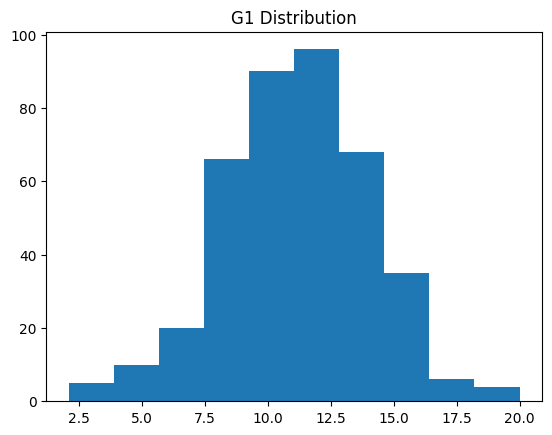

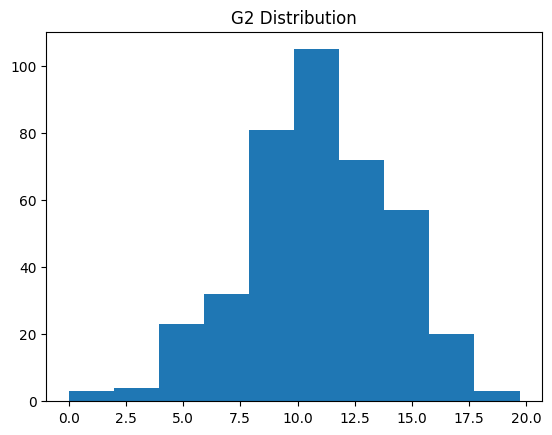

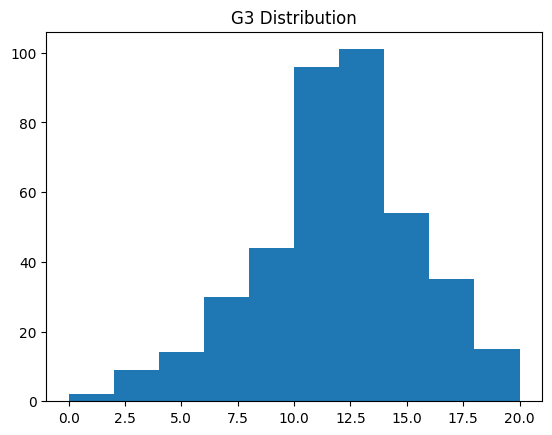

In [12]:
plt.hist(df["G1"],bins = 10)
plt.title("G1 Distribution")
plt.show()

plt.hist(df["G2"], bins=10)
plt.title("G2 Distribution")
plt.show()

plt.hist(df["G3"], bins=10)
plt.title("G3 Distribution")
plt.show()

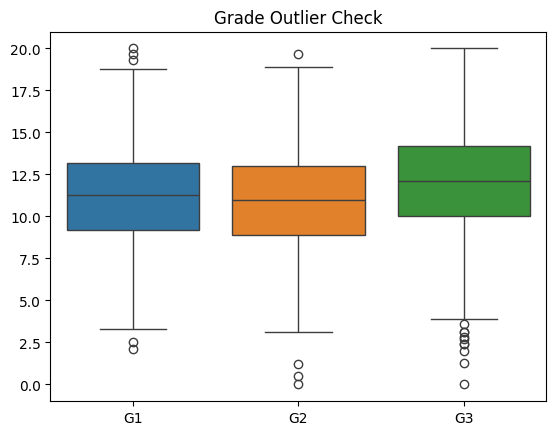

In [13]:
sns.boxplot(data=df[["G1","G2","G3"]])
plt.title("Grade Outlier Check")
plt.show()

# sns.boxplot(x=df["G1"])
# plt.show()

# sns.boxplot(x=df["G2"])
# plt.show()

# sns.boxplot(x=df["G3"])
# plt.show()

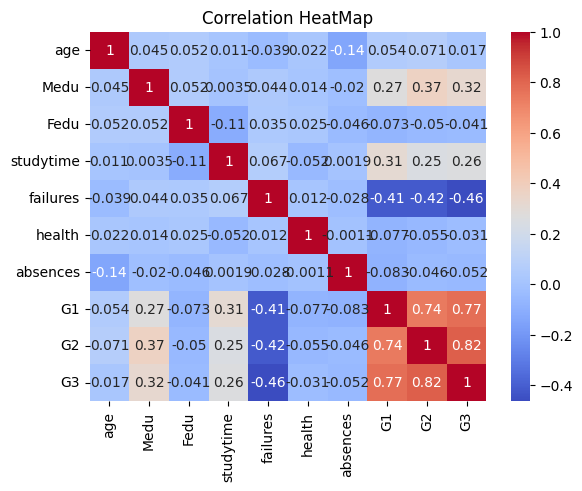

In [14]:
corr = df.corr(numeric_only = True)
sns.heatmap(corr,annot = True,cmap="coolwarm")
plt.title("Correlation HeatMap")
plt.show()


In [15]:
x = df.drop("G3",axis=1)
y = df["G3"]

x = pd.get_dummies(x,drop_first = True,dtype = int)

In [16]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size = 0.2,random_state = 42
)

In [18]:
lr = LinearRegression()
lr.fit(x_train,y_train)
y_pred_lr = lr.predict(x_test)
print("Linear Regression trained")

Linear Regression trained


In [20]:
dt = DecisionTreeRegressor(random_state =42)
dt.fit(x_train,y_train)
y_pred_dt = dt.predict(x_test)

print("Decision Tree trained")

Decision Tree trained


In [21]:
results = pd.DataFrame({
    'Model' : ['Linear Regression ','Decision Tree'],
    'MAE'   :[
        mean_absolute_error(y_test,y_pred_lr),
        mean_absolute_error(y_test,y_pred_dt)
    ],
    'MSE'   :[
        mean_squared_error(y_test,y_pred_lr),
        mean_squared_error(y_test,y_pred_dt)
    ],
    'RMSE'  :[
        np.sqrt(mean_squared_error(y_test,y_pred_lr)),
        np.sqrt(mean_squared_error(y_test,y_pred_dt))
    ],
    'R2'    :[
        r2_score(y_test,y_pred_lr),
        r2_score(y_test,y_pred_dt)
    ]   
})

results.round(3)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1.462,3.392,1.842,0.723
1,Decision Tree,2.091,6.714,2.591,0.451


In [25]:
scoring ={
    'MAE' : 'neg_mean_absolute_error',
    'MSE' : 'neg_mean_squared_error',
    'R2'  :'r2'
}
lr_cv = cross_validate(LinearRegression(),x,y,cv=5,scoring=scoring)
dt_cv = cross_validate(DecisionTreeRegressor(random_state=42),x,y,cv=5,scoring = scoring)

cv_results = pd.DataFrame({
    'Model' :['Linear Regression ','Decision Tree'],
    'Mean MAE':[-lr_cv['test_MAE'].mean(),-dt_cv['test_MAE'].mean()],
    'Mean MSE':[-lr_cv['test_MSE'].mean(),-dt_cv['test_MSE'].mean()],
    'Mean RMSE':[np.sqrt(-lr_cv['test_MSE']).mean(),np.sqrt(-dt_cv['test_MSE']).mean()],
    'Mean R2':[lr_cv['test_R2'].mean(),dt_cv['test_R2'].mean()]
    
})

cv_results.round(3)





,Model,Mean MAE,Mean MSE,Mean RMSE,Mean R2
0,Linear Regression,1.560,3.726,1.924,0.711
1,Decision Tree,2.233,8.161,2.847,0.354


In [23]:
cv = cross_validate(LinearRegression(),x,y,cv=5,scoring="r2")
print("Mean R2:",round(cv['test_score'].mean(),3))

Mean R2: 0.711


In [26]:
bag = BaggingRegressor(
    estimator = DecisionTreeRegressor(random_state=42),
    n_estimators = 50,
    random_state = 42
)
bag.fit(x_train,y_train)
y_pred_bag = bag.predict(x_test)

In [27]:
bag_results = pd.DataFrame({
    'Model': ['Decision Tree', 'Bagging with Decision Trees'],
    'MAE': [
        mean_absolute_error(y_test, y_pred_dt),
        mean_absolute_error(y_test, y_pred_bag)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred_dt),
        mean_squared_error(y_test, y_pred_bag)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_dt)),
        np.sqrt(mean_squared_error(y_test, y_pred_bag))
    ],
    'R2': [
        r2_score(y_test, y_pred_dt),
        r2_score(y_test, y_pred_bag)
    ]
})
bag_results.round(3)

,Model,MAE,MSE,RMSE,R2
0,Decision Tree,2.091,6.714,2.591,0.451
1,Bagging with Decision Trees,1.458,3.374,1.837,0.724
